# Stonks Rebuild v3: Cross-Sectional XGBoost with Turnover Controls

Adds cross-sectional targets, VIX/market beta features, weekly rebalance + hold-threshold to cut turnover, and val-based threshold tuning.


## 1) Configuration


In [24]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from pathlib import Path
from dataclasses import dataclass
from typing import Dict, List, Tuple
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
try:
    from xgboost import XGBClassifier  
except ModuleNotFoundError:
    XGBClassifier = None 

plt.style.use('seaborn-v0_8')


In [25]:
from dataclasses import dataclass

@dataclass(frozen=True)
class Config:
    universe: List[str]
    benchmark: str
    start: str
    end: str
    backtest_start: str
    horizon_days: int
    vol_adjust_labels: bool
    use_cross_sectional_targets: bool
    cs_target_quantile: float
    train_lookback_days: int
    val_window_days: int
    min_training_samples: int
    transaction_cost_bps: float
    top_k: int
    long_short: bool
    rebalance: str 
    hold_threshold: float 
    random_state: int
    decision_threshold: float | None
    target_metric: str
    risk_filter_sma: int | None
    xgb_params: Dict[str, float]

CFG = Config(
universe = [
        # Tech & Comm
        "AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "META", "TSLA", "AMD", "CRM", "NFLX", "ADBE", "INTC", "CSCO",
        # Finance
        "JPM", "BAC", "WFC", "C", "GS", "MS", "V", "MA", "BRK-B",
        # Healthcare
        "JNJ", "UNH", "PFE", "MRK", "ABBV", "LLY", "TMO", "DHR",
        # Consumer
        "WMT", "PG", "KO", "PEP", "COST", "HD", "MCD", "NKE", "PM",
        # Energy & Ind
        "XOM", "CVX", "COP", "SLB", "BA", "CAT", "GE", "UPS", "UNP",
        # Utilities & Telecom
        "NEE", "T", "VZ", "DIS", "CMCSA"
    ],
    benchmark="SPY",
    start="2000-01-01",
    end="2026-12-31",
    backtest_start="2020-01-01",
    horizon_days=1,
    vol_adjust_labels=True,
    use_cross_sectional_targets=False,
    cs_target_quantile=0.6,
    train_lookback_days=504,
    val_window_days=21,
    min_training_samples=50,
    transaction_cost_bps=2.0, # check this later 5 bps is normal 2 bps is low
    top_k=3,
    long_short=True,
    rebalance='D',
    hold_threshold=0.1,
    random_state=42,
    decision_threshold=.8,
    target_metric='precision',
    risk_filter_sma=None,
    xgb_params={
        'n_estimators': 1000,
        'max_depth': 3,
        'learning_rate': 0.05,
        'subsample': 0.9,
        'colsample_bytree': 0.9,
        'min_child_weight': 1.0,
        'gamma': 0.0,
        'reg_lambda': 1.0,
        'reg_alpha': 0.0,
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'tree_method': 'hist',
        'n_jobs': -1,
        'random_state': 42,
    },
)
BT_START = pd.Timestamp(CFG.backtest_start)


## 2) Data Ingestion


In [26]:
def download_ohlcv(tickers: List[str], start: str, end: str) -> Dict[str, pd.DataFrame]:
    data = {}
    for t in tickers:
        df = yf.download(t, start=start, end=end, progress=False)
        if df is None or df.empty:
            print(f"[WARN] No data for {t}")
            continue
        df = df.rename(columns=str.lower)
        df.index = pd.to_datetime(df.index)
        df['ticker'] = t
        data[t] = df
    if not data:
        raise ValueError("No data downloaded; check tickers/network.")
    return data

raw = download_ohlcv(CFG.universe + [CFG.benchmark, '^VIX'], CFG.start, CFG.end)


## 3) Feature Engineering (per ticker)


In [27]:
def safe_build_features(df_in: pd.DataFrame) -> pd.DataFrame:
    df = df_in.copy()
    
    # --- A. Basic Cleaning ---
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    else:
        df.columns = [c[0] if isinstance(c, tuple) else c for c in df.columns]
    df.columns = [str(c).lower() for c in df.columns]
    
    if 'close' not in df.columns: return pd.DataFrame()
    
    # --- B. Base Features ---
    df['log_ret'] = np.log(df['close']).diff()
    
    # --- C. Trend & Volatility (Moving Averages) ---
    for w in [5, 10, 20, 60, 120, 180]:
        # SMA and Volatility
        df[f'sma_{w}'] = df['close'].rolling(w).mean()
        df[f'vol_{w}'] = df['log_ret'].rolling(w).std()
        
        # Distance from SMA (Mean Reversion)
        if f'sma_{w}' in df.columns:
            df[f'dist_sma_{w}'] = (df['close'] - df[f'sma_{w}']) / (df[f'sma_{w}'] + 1e-8)

    # --- D. Bollinger Bands (Relative Price) ---
    bb_window = 20
    sma_20 = df['close'].rolling(bb_window).mean()
    std_20 = df['close'].rolling(bb_window).std()
    
    df['bb_width'] = (4 * std_20) / (sma_20 + 1e-8)
    df['bb_pos'] = (df['close'] - (sma_20 - 2*std_20)) / (4*std_20 + 1e-8)

    # --- E. Stochastic Oscillator (Momentum) ---
    stoch_window = 14
    low_min = df['low'].rolling(stoch_window).min()
    high_max = df['high'].rolling(stoch_window).max()
    df['stoch_k'] = 100 * (df['close'] - low_min) / (high_max - low_min + 1e-8)
    
    # --- F. RSI (Relative Strength) ---
    rsi_window = 14
    delta = df['close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(rsi_window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(rsi_window).mean()
    rs = gain / (loss + 1e-8)
    df['rsi'] = 100 - (100 / (1 + rs))

    # --- G. NEW: MACD (Trend Strength) ---
    # Normalized by price so it's comparable across stocks
    ema_12 = df['close'].ewm(span=12, adjust=False).mean()
    ema_26 = df['close'].ewm(span=26, adjust=False).mean()
    macd_line = ema_12 - ema_26
    macd_signal = macd_line.ewm(span=9, adjust=False).mean()
    df['macd_hist_norm'] = (macd_line - macd_signal) / (df['close'] + 1e-8)

    # --- H. NEW: ATR (Normalized Volatility) ---
    # True Range
    tr1 = df['high'] - df['low']
    tr2 = (df['high'] - df['close'].shift(1)).abs()
    tr3 = (df['low'] - df['close'].shift(1)).abs()
    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    atr = tr.rolling(14).mean()
    df['atr_rel'] = atr / (df['close'] + 1e-8) # Normalized by price

    # --- I. NEW: Volume Ratio (Liquidity Surges) ---
    # Is volume higher than normal today?
    vol_sma_20 = df['volume'].rolling(20).mean()
    df['vol_rel'] = df['volume'] / (vol_sma_20 + 1e-8)

    # --- J. NEW: Lagged Returns (Autocorrelation) ---
    # What happened yesterday often predicts today
    for lag in [1, 2, 3, 5]:
        df[f'log_ret_lag_{lag}'] = df['log_ret'].shift(lag)

    return df.dropna()

## 4) Labels, Panel, Cross-Sectional Targets & Ranks


In [28]:
import pandas as pd
import numpy as np


# 2. PREPARE BENCHMARK & VIX
print("Rebuilding features with Advanced Indicators...")
features_by_symbol = {}

# Ensure Benchmark is ready
if CFG.benchmark in raw:
    bench = safe_build_features(raw[CFG.benchmark])
else:
    print(f"Warning: Benchmark {CFG.benchmark} not found in raw.")
    bench = pd.DataFrame()

# Ensure VIX is ready
if '^VIX' in raw:
    vix = raw['^VIX'].copy()
    if isinstance(vix.columns, pd.MultiIndex): vix.columns = vix.columns.get_level_values(0)
    vix.columns = [str(c).lower() for c in vix.columns]
    vix = vix.rename(columns={'close': 'vix_close'})
else:
    vix = pd.DataFrame()

# 3. MAIN LOOP
for t in CFG.universe:
    if t not in raw: continue
        
    feats = safe_build_features(raw[t])
    if feats.empty: continue
        
    # Merge Benchmark Returns
    if not bench.empty and 'log_ret' in bench:
        feats['bench_log_ret'] = bench['log_ret'].reindex(feats.index).fillna(0)
        # Calculate Beta
        cov20 = feats['log_ret'].rolling(20).cov(feats['bench_log_ret'])
        var20 = feats['bench_log_ret'].rolling(20).var()
        feats['beta_20'] = cov20 / (var20 + 1e-8)
    
    # Merge VIX
    if not vix.empty and 'vix_close' in vix:
        vix_aligned = vix.reindex(feats.index).ffill()
        feats['vix_close'] = vix_aligned['vix_close']
        
    features_by_symbol[t] = feats

print(f"Features rebuilt for {len(features_by_symbol)} tickers.")

# 4. LABEL AND ASSEMBLE PANEL
def add_labels(df, horizon, vol_adjust):
    out = df.copy()
    fwd = out['log_ret'].rolling(horizon).sum().shift(-horizon)
    if vol_adjust:
        vol = out['log_ret'].rolling(20).std()
        fwd = fwd / (vol + 1e-6)
    out['y_reg'] = fwd
    out['y_cls'] = (fwd > 0).astype(int)
    return out

labeled = {}
for t, df in features_by_symbol.items():
    l_df = add_labels(df, CFG.horizon_days, CFG.vol_adjust_labels)
    if not l_df.empty: labeled[t] = l_df

# Assemble Panel
frames = []
for t, df in labeled.items():
    tmp = df.copy()
    tmp['ticker'] = t
    frames.append(tmp)

panel = pd.concat(frames).sort_index()
panel.index.name = 'date'
panel = panel.dropna(subset=['y_reg', 'y_cls'])

if CFG.use_cross_sectional_targets:
    ranks = panel.groupby(level=0)['y_reg'].rank(pct=True)
    panel['y_cls'] = (ranks >= CFG.cs_target_quantile).astype(int)

FEATURES = [c for c in panel.columns if c not in {'ticker', 'y_reg', 'y_cls'}]
print(f"Success! Panel Shape: {panel.shape}")


Rebuilding features with Advanced Indicators...
Features rebuilt for 53 tickers.
Success! Panel Shape: (317592, 41)


In [29]:
# Keep only numeric feature columns (drop ticker/objects)
numeric_cols = [c for c in FEATURES if c in panel.columns and pd.api.types.is_numeric_dtype(panel[c])]
FEATURES = numeric_cols
# Ensure panel has no object columns left in features
panel_features_only = panel[numeric_cols + ['ticker','y_reg','y_cls']]


In [30]:
# Diagnostics: panel/feature coverage
print('Panel rows:', len(panel), 'Features:', len(FEATURES))
print('Date range:', panel.index.min(), 'to', panel.index.max())
print('Per-ticker counts:', panel['ticker'].value_counts().head())
bt_dates = sorted(panel.loc[panel.index >= BT_START].index.unique())
print('Backtest dates >=', BT_START.date(), ':', len(bt_dates))


Panel rows: 317592 Features: 38
Date range: 2000-10-16 00:00:00 to 2025-12-09 00:00:00
Per-ticker counts: ticker
GS      6325
PG      6325
CAT     6325
CSCO    6325
XOM     6325
Name: count, dtype: int64
Backtest dates >= 2020-01-01 : 1493


In [31]:
# Cross-sectional percentile ranks for select features
RANK_COLS = [c for c in FEATURES if isinstance(c, str) and c.startswith(('roc_','rsi','macd','sma_'))]
rank_frames = []
for dt, group in panel.groupby(level=0):
    ranked = group.copy()
    for col in RANK_COLS:
        if col in ranked.columns:
            ranked[f'{col}_pct'] = ranked[col].rank(pct=True)
    rank_frames.append(ranked)
panel = pd.concat(rank_frames).sort_index()
FEATURES = [c for c in panel.columns if c not in {'ticker','y_reg','y_cls'}]


## 5) Benchmark State / Regime Filter


In [32]:
def benchmark_state(raw_dict: Dict[str, pd.DataFrame], symbol: str, sma_window: int | None) -> pd.Series:
    df = raw_dict[symbol].copy()
    df.index = pd.to_datetime(df.index)
    df['log_ret'] = np.log(df['close']).diff().fillna(0.0)
    df['equity'] = (1 + df['log_ret']).cumprod()
    if sma_window is None:
        return pd.Series(True, index=df.index)
    sma = df['equity'].rolling(sma_window).mean()
    return (df['equity'] > sma).reindex(df.index).fillna(False)

risk_on = benchmark_state(raw, CFG.benchmark, CFG.risk_filter_sma)


## 6) Metrics + Helpers


In [33]:
def sharpe_ratio(daily_returns: pd.Series, risk_free_daily: float = 0.0) -> float:
    excess = daily_returns - risk_free_daily
    std = excess.std(ddof=0)
    if std == 0 or np.isnan(std):
        return 0.0
    return np.sqrt(252) * excess.mean() / std


def max_drawdown(equity_curve: pd.Series) -> float:
    if equity_curve.empty:
        return 0.0
    peak = equity_curve.cummax()
    dd = equity_curve / peak - 1.0
    return float(dd.min())


def split_train_val(train: pd.DataFrame, val_window_days: int) -> Tuple[pd.DataFrame, pd.DataFrame | None]:
    if val_window_days <= 0 or train.empty:
        return train, None
    cutoff = train.index.max() - pd.tseries.offsets.BDay(val_window_days)
    val = train.loc[train.index > cutoff]
    core = train.loc[train.index <= cutoff]
    if val.empty or core.empty:
        return train, None
    return core, val


def optimize_threshold(y_true: np.ndarray, prob: np.ndarray, metric: str = 'f1') -> float:
    if y_true.size == 0 or prob.size == 0 or np.unique(y_true).size < 2:
        return 0.5
    thresholds = np.linspace(0.3, 0.7, 9)
    best, best_score = 0.5, -np.inf
    for thr in thresholds:
        preds = (prob >= thr).astype(int)
        if metric == 'precision':
            score = precision_score(y_true, preds, zero_division=0)
        elif metric == 'recall':
            score = recall_score(y_true, preds, zero_division=0)
        else:
            score = f1_score(y_true, preds, zero_division=0)
        if score > best_score:
            best_score, best = score, float(thr)
    return best


def set_scale_pos_weight(model: object, y: np.ndarray) -> None:
    pos = float(np.sum(y == 1))
    neg = float(np.sum(y == 0))
    if pos == 0 or neg == 0 or not hasattr(model, 'set_params'):
        return
    try:
        model.set_params(scale_pos_weight=neg / pos)
    except ValueError:
        pass


def make_model(cfg: Config) -> XGBClassifier:
    if XGBClassifier is None:
        raise ImportError("Install xgboost: pip install xgboost")
    return XGBClassifier(**cfg.xgb_params)


## 7) Walk-Forward Backtest with Hold-Threshold


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import List, Dict, Optional
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

@dataclass
class BacktestResult:
    daily: pd.DataFrame
    preds: pd.DataFrame
    cls_report: Dict[str, float]

def _apply_hold_threshold(selected: List[str], scores: Dict[str, float], prev: set[str], top_k: int, gap: float, higher_is_better: bool = True) -> List[str]:
    if gap <= 0 or not prev or not selected:
        return selected[:top_k]
    
    # 1. Identify the score of the "last in" candidate (the cutoff)
    candidates = selected[:top_k]
    if not candidates: 
        return []
        
    cutoff_ticker = candidates[-1]
    cutoff_score = scores.get(cutoff_ticker, -np.inf if higher_is_better else np.inf)

    # 2. Check previous holders
    kept = []
    for t in prev:
        if t in scores and t not in candidates:
            s = scores[t]
            # Check if previous holder is "close enough" to the cutoff to stay
            if higher_is_better:
                if cutoff_score - s <= gap:
                    kept.append(t)
            else:
                if s - cutoff_score <= gap:
                    kept.append(t)
    
    # 3. Combine and resort
    final_set = set(candidates + kept)
    final_list = [t for t in final_set if t in scores]
    return sorted(final_list, key=lambda x: scores[x], reverse=higher_is_better)[:top_k]

    

In [35]:
def walk_forward_backtest(panel: pd.DataFrame, features: List[str], cfg) -> BacktestResult:
    # --- 1. OPTIMIZATION: Prepare data ONCE ---
    panel_num = panel.copy()
    for col in panel_num.columns:
        if col != 'ticker' and panel_num[col].dtype == 'object':
            panel_num[col] = pd.to_numeric(panel_num[col], errors="coerce")
    
    dates = sorted(panel.loc[panel.index >= BT_START].index.unique())
    scaler = StandardScaler()
    model = make_model(cfg)

    recs = []
    pred_rows = []
    held_longs_prev: set[str] = set()
    held_shorts_prev: set[str] = set()
    tc = cfg.transaction_cost_bps / 10000.0

    print(f"Starting Backtest: {len(dates)} steps from {dates[0]} to {dates[-1]}")

    for i, current_date in enumerate(dates):
        if i % 100 == 0: print(f"... processing {current_date.date()}")

        # Helper to skip day safely
        def append_flat():
            recs.append({'date': current_date, 'day_ret': 0.0, 'longs': 0, 'shorts': 0})

        # Check Rebalance Schedule
        if cfg.rebalance == 'D' and current_date.weekday() != 0:
            append_flat()
            continue
        
        # Check Risk On/Off
        # is_risk_on = risk_on.get(current_date, False) if 'risk_on' in globals() else True
        # if not is_risk_on:
        #     append_flat()
        #     held_longs_prev, held_shorts_prev = set(), set()
        #     continue

        cutoff = current_date - pd.tseries.offsets.BDay(cfg.train_lookback_days)
        train_mask = (panel_num.index < current_date) & (panel_num.index >= cutoff)
        test_mask = panel_num.index == current_date
        
        train = panel_num.loc[train_mask]
        test = panel_num.loc[test_mask]

        if len(train) < cfg.min_training_samples or test.empty:
            append_flat()
            continue

        # --- Training ---
        core, val = split_train_val(train, cfg.val_window_days)
        X_tr, y_tr = core[features].values, core['y_cls'].values
        X_te = test[features].values
        
        scaler.fit(X_tr)
        X_tr_sc = scaler.transform(X_tr)
        X_te_sc = scaler.transform(X_te)
        
        try:
            model.fit(X_tr_sc, y_tr)
        except Exception:
            model.fit(X_tr_sc, y_tr)

        prob_up = model.predict_proba(X_te_sc)[:, 1]
        
        # Store predictions
        pred_rows.append(pd.DataFrame({           
            'date': current_date,
            'ticker': test['ticker'].values,
            'y_true': test['y_cls'].values,
            'y_reg': test['y_reg'].values,
            'p_up': prob_up,
            'y_pred': (prob_up >= .8).astype(int),
        }))

        # --- Portfolio Construction ---
        scores = dict(zip(test['ticker'].values, prob_up))
        
        # FIX: We now include 'ret_1d' in the day frame for accurate P&L
        day_frame = pd.DataFrame({
            'ticker': test['ticker'].values, 
            'p_up': prob_up, 
            'y_reg': test['y_reg'].values,
            'ret_1d': test['ret_1d'].values
        })
        
        # 1. Clean Poison Data
        # Filter out massive data errors
        bad_data_mask = day_frame['ret_1d'] <= -0.9
        if bad_data_mask.any():
            day_frame = day_frame[~bad_data_mask]
            
        day_frame['ret_1d'] = day_frame['ret_1d'].fillna(0.0)
        
        # Define valid tickers (whitelist)
        valid_tickers = set(day_frame['ticker'].values)

        # 2. Select Longs (Highest Probability)
        longs = day_frame.sort_values('p_up', ascending=False)['ticker'].tolist()
        longs = _apply_hold_threshold(longs, scores, held_longs_prev, cfg.top_k, cfg.hold_threshold, True)
        longs = [t for t in longs if t in valid_tickers]
        
        # 3. Select Shorts (Lowest Probability)
        shorts = []
        if cfg.long_short:
            shorts = day_frame.sort_values('p_up', ascending=True)['ticker'].tolist()
            shorts = _apply_hold_threshold(shorts, scores, held_shorts_prev, cfg.top_k, cfg.hold_threshold, False)
            shorts = [t for t in shorts if t in valid_tickers]

        # 4. Calculate Returns using 1-Day Returns (Not 7-Day Target)
        long_ret = day_frame.set_index('ticker').loc[longs, 'ret_1d'].mean() if longs else 0.0
        short_ret = -day_frame.set_index('ticker').loc[shorts, 'ret_1d'].mean() if shorts else 0.0

        # Costs
        held_longs = set(longs)
        held_shorts = set(shorts)
        entries = len(held_longs - held_longs_prev) + len(held_shorts - held_shorts_prev)
        exits = len(held_longs_prev - held_longs) + len(held_shorts_prev - held_shorts)
        trades = entries + exits
        
        denom = len(longs) + len(shorts)
        cost = (trades * tc / max(1, denom)) if denom > 0 else 0.0

        day_ret = (long_ret + short_ret) - cost
        
        # Bankruptcy Protection (Floor at -99%)
        if day_ret <= -0.99:
            day_ret = -0.99
            
        recs.append({'date': current_date, 'day_ret': day_ret, 'longs': len(longs), 'shorts': len(shorts)})
        held_longs_prev = held_longs
        held_shorts_prev = held_shorts

    if not recs:
        raise ValueError("No results generated.")

    daily = pd.DataFrame(recs).set_index('date').sort_index()
    daily['day_ret'] = daily['day_ret'].fillna(0.0)
    daily['equity'] = (1 + daily['day_ret']).cumprod()
    
    preds = pd.concat(pred_rows).sort_values(['date','ticker']).reset_index(drop=True)
    
    cls_report = {}
    if not preds.empty:
        cls_report = {
            'accuracy': accuracy_score(preds['y_true'], preds['y_pred']),
            'precision': precision_score(preds['y_true'], preds['y_pred'], zero_division=0),
            'recall': recall_score(preds['y_true'], preds['y_pred'], zero_division=0),
            'f1': f1_score(preds['y_true'], preds['y_pred'], zero_division=0),
        }
        
    return BacktestResult(daily=daily, preds=preds, cls_report=cls_report)

## 8) Run Backtest


In [36]:
import optuna
from sklearn.metrics import precision_score
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

def dynamic_tune(panel_data, cutoff_date, features, n_trials=20):
    """
    Tunes hyperparameters to maximize PRECISION.
    """
    history = panel_data[panel_data.index < cutoff_date].copy()
    
    if len(history) < 500: return None
        
    dates = sorted(history.index.unique())
    split_idx = int(len(dates) * 0.8)
    split_date = dates[split_idx]
    
    train = history[history.index < split_date]
    val = history[history.index >= split_date]
    
    X_tr, y_tr = train[features].values, train['y_cls'].values
    X_val, y_val = val[features].values, val['y_cls'].values
    
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_val = scaler.transform(X_val)

    def objective(trial):
        param = {
            'n_estimators': trial.suggest_int('n_estimators', 200, 1000),
            'max_depth': trial.suggest_int('max_depth', 3, 5), # Keep simple
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 0.9),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.9),
            'min_child_weight': trial.suggest_int('min_child_weight', 2, 10), # Higher = more conservative
            'gamma': trial.suggest_float('gamma', 0.1, 5.0), # Higher gamma = conservative
            'reg_alpha': trial.suggest_float('reg_alpha', 0.1, 10.0, log=True),
            'objective': 'binary:logistic',
            'eval_metric': 'logloss',
            'n_jobs': -1,
            'verbosity': 0,
            'random_state': 42
        }
        
        model = XGBClassifier(**param)
        model.fit(X_tr, y_tr)
        
        # Predict Probabilities
        probs = model.predict_proba(X_val)[:, 1]
        
        # We optimize for Precision at a slightly higher threshold (e.g., 0.52)
        # This encourages the model to be accurate on its confident calls
        preds = (probs > 0.52).astype(int)
        
        # Guard against zero divisions (if no buys are signaled)
        if sum(preds) == 0: return 0.0
            
        return precision_score(y_val, preds)

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=n_trials)
    
    return study.best_params

In [37]:
def walk_forward_with_tuning(panel, features, cfg, retune_days=126, min_prob=0.53):
    # Setup
    dates = sorted(panel.loc[panel.index >= pd.Timestamp(cfg.backtest_start)].index.unique())
    scaler = StandardScaler()
    
    # Use existing params as baseline
    current_params = cfg.xgb_params.copy()
    
    recs = []
    pred_rows = []
    held_longs = set()
    tc = cfg.transaction_cost_bps / 10000.0

    print(f"Starting Precision-Focused Backtest. Min Prob: {min_prob}")

    for i, current_date in enumerate(dates):
        # Re-tune periodically
        if i % retune_days == 0:
            print(f"... [Day {i}] Tuning for Precision prior to {current_date.date()} ...")
            new_params = dynamic_tune(panel, current_date, features, n_trials=50)
            if new_params:
                current_params.update(new_params)
        
        # Get Data
        cutoff = current_date - pd.tseries.offsets.BDay(cfg.train_lookback_days)
        train = panel[(panel.index < current_date) & (panel.index >= cutoff)]
        test = panel[panel.index == current_date]
        
        if len(train) < 100 or test.empty:
            recs.append({'date': current_date, 'day_ret': 0.0})
            continue

        # Train
        model = XGBClassifier(**current_params)
        X_tr = train[features].values
        y_tr = train['y_cls'].values
        X_te = test[features].values
        
        scaler.fit(X_tr)
        model.fit(scaler.transform(X_tr), y_tr)
        
        # Predict
        probs = model.predict_proba(scaler.transform(X_te))[:, 1]
        
        # --- NEW PORTFOLIO LOGIC ---
        # 1. Filter candidates by Minimum Probability threshold
        day_frame = pd.DataFrame({'ticker': test['ticker'], 'p_up': probs, 'ret_1d': test['ret_1d']})
        
        # Only consider stocks with p_up > min_prob
        confident_picks = day_frame[day_frame['p_up'] > min_prob]
        
        # 2. Select Top K from the confident picks
        if not confident_picks.empty:
            selected = confident_picks.nlargest(cfg.top_k, 'p_up')['ticker'].tolist()
        else:
            selected = [] # No trades if no confidence
            
        # 3. Calculate Return
        if selected:
            # Equal weight return of selected stocks
            # Important: We must use the FUTURE return (ret_1d) we calculated earlier
            # Ensure 'ret_1d' is aligned correctly in the day_frame
            day_ret = day_frame[day_frame['ticker'].isin(selected)]['ret_1d'].mean()
            
            # Costs
            turnover = len(set(selected) - held_longs)
            cost = (turnover * tc) / len(selected) # Cost proportional to portfolio size
            
            recs.append({'date': current_date, 'day_ret': day_ret - cost})
        else:
            # Cash return (0%)
            recs.append({'date': current_date, 'day_ret': 0.0})
            
        held_longs = set(selected)
        
        # Save predictions for analysis
        pred_rows.append(pd.DataFrame({
            'date': current_date,
            'ticker': test['ticker'],
            'y_true': test['y_cls'],
            'p_up': probs
        }))

    daily = pd.DataFrame(recs).set_index('date')
    daily['equity'] = (1 + daily['day_ret'].fillna(0)).cumprod()
    preds = pd.concat(pred_rows)
    
    return daily, preds


In [38]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# --- 1. Ensure Target Variable Exists ---
# This step is CRITICAL. We calculate the 1-day forward return.
if 'ret_1d' not in panel.columns:
    print("Calculating 'ret_1d' (Next Day Return)...")
    # Shift log_ret backwards by 1 to get next day's return for today's row
    panel['ret_1d'] = panel.groupby('ticker')['log_ret'].shift(-1).fillna(0.0)
else:
    print("'ret_1d' already exists.")

# --- 2. Run the Walk-Forward Backtest with Tuning ---
# Make sure FEATURES is defined and doesn't include 'ret_1d' or 'ticker' etc.
if 'FEATURES' not in locals():
    # Fallback feature definition if not already defined
    non_feature_cols = {'ticker', 'y_reg', 'y_cls', 'ret_1d', 'log_ret', 'bench_log_ret', 'date'}
    FEATURES = [c for c in panel.columns if c not in non_feature_cols]

print(f"Starting backtest with {len(FEATURES)} features.")

# Call your function (assuming dynamic_tune is already defined in your notebook)
daily_res, predictions = walk_forward_with_tuning(panel, FEATURES, CFG, retune_days=126, min_prob=0.6)

print("\n--- Backtest Complete ---")
print(f"Final Equity: {daily_res['equity'].iloc[-1]:.4f}")

Calculating 'ret_1d' (Next Day Return)...
Starting backtest with 46 features.
Starting Precision-Focused Backtest. Min Prob: 0.6
... [Day 0] Tuning for Precision prior to 2020-01-02 ...
... [Day 126] Tuning for Precision prior to 2020-07-02 ...
... [Day 252] Tuning for Precision prior to 2020-12-31 ...
... [Day 378] Tuning for Precision prior to 2021-07-02 ...
... [Day 504] Tuning for Precision prior to 2021-12-31 ...
... [Day 630] Tuning for Precision prior to 2022-07-05 ...
... [Day 756] Tuning for Precision prior to 2023-01-03 ...
... [Day 882] Tuning for Precision prior to 2023-07-06 ...
... [Day 1008] Tuning for Precision prior to 2024-01-04 ...
... [Day 1134] Tuning for Precision prior to 2024-07-08 ...
... [Day 1260] Tuning for Precision prior to 2025-01-06 ...
... [Day 1386] Tuning for Precision prior to 2025-07-10 ...

--- Backtest Complete ---
Final Equity: 1.6726


In [39]:
class BacktestResult:
    def __init__(self, daily, preds):
        self.daily = daily
        self.preds = preds
        # Calculate a simple report for compatibility
        self.cls_report = {
            'precision': precision_score(preds['y_true'], (preds['p_up'] > 0.5).astype(int)),
            'accuracy': accuracy_score(preds['y_true'], (preds['p_up'] > 0.5).astype(int))
        }

# 3. Create the 'bt' object
bt = BacktestResult(daily_res, predictions)
print("Backtest complete. 'bt' variable is now defined.")

Backtest complete. 'bt' variable is now defined.


Restoring 'y_reg' to predictions dataframe...


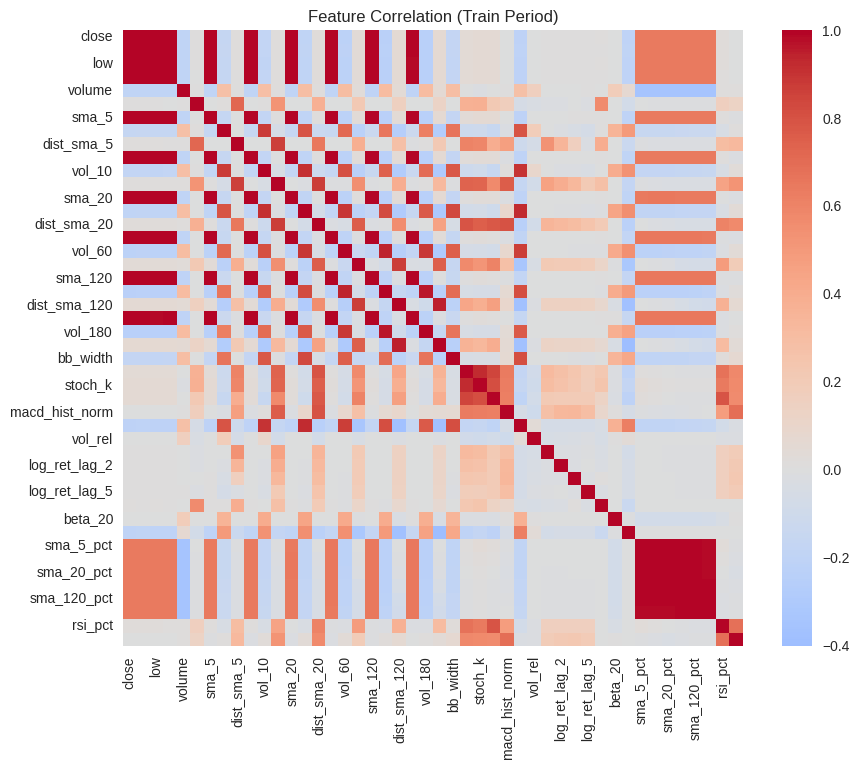

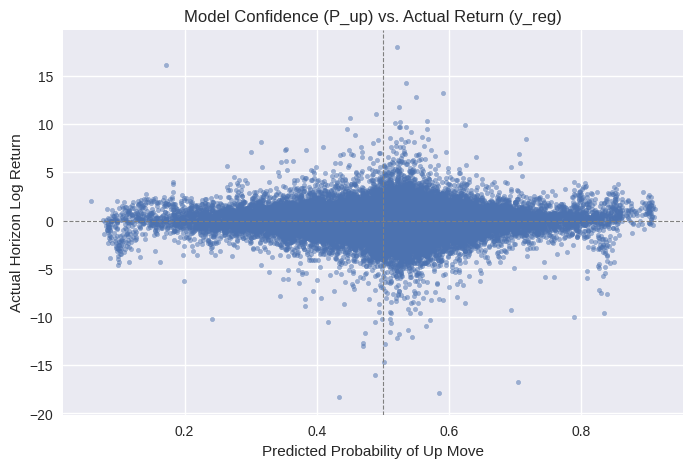

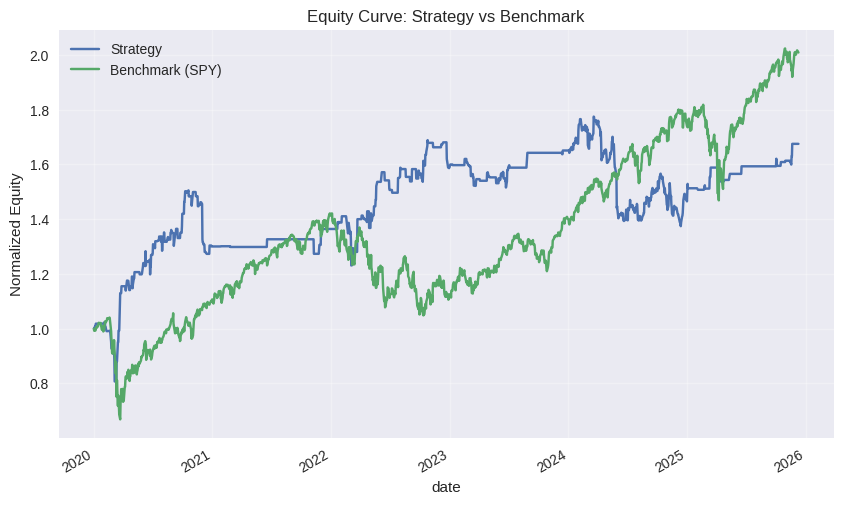

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. FIX: Restore 'y_reg' to bt.preds
if 'y_reg' not in bt.preds.columns:
    print("Restoring 'y_reg' to predictions dataframe...")
    
    # Prepare Targets: Ensure 'date' is a column, not an index
    targets = panel[['ticker', 'y_reg']].copy()
    if targets.index.name == 'date':
        targets = targets.reset_index()
    
    # Prepare Preds: Remove ambiguity if 'date' is both index and column
    if bt.preds.index.name == 'date':
        # If 'date' is already a column, just unset the index name
        if 'date' in bt.preds.columns:
            bt.preds.index.name = None
        else:
            # If 'date' is only in index, move it to column
            bt.preds = bt.preds.reset_index()

    # Double check to ensure 'date' is a column in both
    if 'date' not in bt.preds.columns:
        # Fallback: maybe index has no name but contains dates?
        bt.preds['date'] = bt.preds.index
        
    # Left merge to keep only the rows we predicted on
    bt.preds = pd.merge(bt.preds, targets, on=['date', 'ticker'], how='left')

# 2. Plot Correlation Matrix (Training Data)
train_mask = panel.index < BT_START
train_sample = panel.loc[train_mask, FEATURES]
train_sample = train_sample.select_dtypes(include=['number'])

if not train_sample.empty:
    corr = train_sample.corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
    plt.title('Feature Correlation (Train Period)')
    plt.show()

# 3. Plot P(up) vs Forward Return
plt.figure(figsize=(8, 5))
plt.scatter(bt.preds["p_up"], bt.preds["y_reg"], s=10, alpha=0.5)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0.5, color='gray', linestyle='--', linewidth=0.8)
plt.title("Model Confidence (P_up) vs. Actual Return (y_reg)")
plt.xlabel("Predicted Probability of Up Move")
plt.ylabel("Actual Horizon Log Return")
plt.show()

# 4. Equity Curve
if CFG.benchmark in raw:
    # Get benchmark data
    bench_data = raw[CFG.benchmark].copy()
    
    # Ensure column access is robust (handle MultiIndex)
    if isinstance(bench_data.columns, pd.MultiIndex):
        bench_data.columns = bench_data.columns.get_level_values(0)
    bench_data.columns = [str(c).lower() for c in bench_data.columns]
    
    # Extract close prices as a 1D Series
    bench_series = bench_data['close'].squeeze()
    
    # Calculate returns
    bench_ret = np.log(bench_series).diff().fillna(0.0)
    
    # Reindex to match strategy dates
    bench_ret = bench_ret.reindex(bt.daily.index).fillna(0.0)
    
    # Calculate equity curve
    bench_equity = (1 + bench_ret).cumprod()
    
    # Create aligned DataFrame with explicit 1D Series
    aligned = pd.DataFrame({
        "Strategy": bt.daily['equity'],
        f"Benchmark ({CFG.benchmark})": bench_equity
    }).dropna()
    
    # Normalize to 1.0 start
    aligned = aligned / aligned.iloc[0]
    
    # Plot
    aligned.plot(figsize=(10, 6), title="Equity Curve: Strategy vs Benchmark")
    plt.grid(True, alpha=0.3)
    plt.ylabel("Normalized Equity")
    plt.show()

## 9) Benchmark & Plots


In [41]:
print("------ DIAGNOSTIC REPORT ------")
# Find the max value and when it happened
max_val = bt.daily['equity'].max()
max_date = bt.daily['equity'].idxmax()

print(f"Max Equity Value: {max_val}")
print(f"Happened on: {max_date}")

# Check the surrounding days
print("\nSurrounding Data:")
print(bt.daily['equity'].loc[max_date - pd.Timedelta(days=5) : max_date + pd.Timedelta(days=5)])# 1. Did the strategy execute ANY trades?
# (Check if your trade list is empty)
try:
    if hasattr(bt, 'trades'):
        n_trades = len(bt.trades)
        print(f"Total Trades Executed: {n_trades}")
        if n_trades == 0:
            print("!!! CAUSE FOUND: No trades were executed. !!!") 
            print("Check: predictions < threshold? Position sizing = 0? Risk filters too strict?")
    else:
        print("bt.trades not found, skipping trade count check.")
except Exception as e:
    print(f"Could not count trades: {e}")

# 2. Is the Equity Column changing values?
# (If Std Dev is 0, the numbers are identical every single day)
equity_std = bt.daily['equity'].std()
print(f"\nEquity Start: {bt.daily['equity'].iloc[0]}")
print(f"Equity End:   {bt.daily['equity'].iloc[-1]}")
print(f"Equity Variation (Std Dev): {equity_std}")

if equity_std == 0:
    print("!!! CAUSE FOUND: Equity is mathematically constant. !!!")
elif equity_std < 0.0001:
    print("!!! CAUSE FOUND: Variance is microscopic. Your position size might be too small.")

# 3. Date Alignment Check
# (Do the benchmark dates actually cover the strategy dates?)
strat_start = bt.daily.index.min()
bench_start = raw[CFG.benchmark].index.min()
bench_end = raw[CFG.benchmark].index.max()

print(f"\nStrategy Start Date: {strat_start}")
print(f"Benchmark Range:     {bench_start} to {bench_end}")

if strat_start < bench_start:
    print("!!! CAUSE FOUND: Strategy starts BEFORE Benchmark data exists.")
    print("Result: Benchmark line will be NaN or flat from fill.")

print("-------------------------------")

------ DIAGNOSTIC REPORT ------
Max Equity Value: 1.77192753438534
Happened on: 2024-03-19 00:00:00

Surrounding Data:
date
2024-03-14    1.688345
2024-03-15    1.700545
2024-03-18    1.710684
2024-03-19    1.771928
2024-03-20    1.771054
2024-03-21    1.757732
2024-03-22    1.758000
Name: equity, dtype: float64
bt.trades not found, skipping trade count check.

Equity Start: 0.9984130338083023
Equity End:   1.6725820223481396
Equity Variation (Std Dev): 0.17106181061761086

Strategy Start Date: 2020-01-02 00:00:00
Benchmark Range:     2000-01-03 00:00:00 to 2025-12-10 00:00:00
-------------------------------


## 10) Metrics & Artifact Export


In [42]:
strategy_sr = sharpe_ratio(bt.daily['day_ret'].dropna())
strategy_mdd = max_drawdown(bt.daily['equity'])
print(f"Strategy Sharpe (annualized): {strategy_sr:.3f}")
print(f"Strategy Max Drawdown: {strategy_mdd:.2%}")
print("Classification metrics:", bt.cls_report)

out_dir = Path('artifacts')
out_dir.mkdir(parents=True, exist_ok=True)
bt.daily.to_csv(out_dir / 'daily_returns_equity.csv')
bt.preds.to_csv(out_dir / 'row_level_predictions.csv', index=False)
print('Saved artifacts to', out_dir.resolve())


Strategy Sharpe (annualized): 0.590
Strategy Max Drawdown: -22.55%
Classification metrics: {'precision': 0.5252271512560128, 'accuracy': 0.5164478257023342}
Saved artifacts to /kaggle/working/artifacts


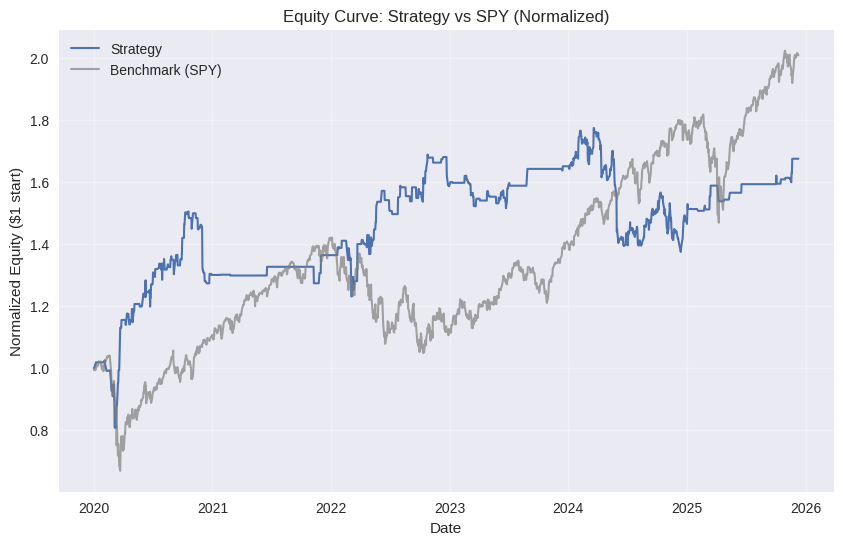

Final Strategy Equity: 1.6752
Strategy Sharpe Ratio: 0.59
Strategy Max Drawdown: -22.55%


In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- ROBUST PLOTTING FIX ---

def ensure_1d_series(data):
    """Helper to force data into a 1D pandas Series."""
    if isinstance(data, pd.DataFrame):
        # If it's a DataFrame, try to squeeze it to a Series
        return data.squeeze()
    if isinstance(data, np.ndarray):
        # If it's a numpy array, flatten it
        return pd.Series(data.ravel())
    return data

# 1. Check if backtest data exists
if 'bt' not in locals() or bt.daily.empty:
    print("Error: 'bt.daily' is empty or not defined. Please run the backtest step first.")
else:
    # 2. Prepare Strategy Data
    # Ensure it's a 1D Series
    strategy_curve = ensure_1d_series(bt.daily['equity'].copy())
    
    # Handle Timezones: Remove them to prevent alignment errors
    if hasattr(strategy_curve.index, 'tz'):
        strategy_curve.index = strategy_curve.index.tz_localize(None)

    # 3. Prepare Benchmark Data
    if CFG.benchmark in raw:
        # Get raw data
        bench_raw = raw[CFG.benchmark].copy()
        
        # FIX: Flatten MultiIndex columns if they exist (common with yfinance)
        if isinstance(bench_raw.columns, pd.MultiIndex):
            bench_raw.columns = bench_raw.columns.get_level_values(0)
        
        # Standardize column names
        bench_raw.columns = [str(c).lower() for c in bench_raw.columns]
        
        # Calculate Returns
        # We use 'close' (or 'adj close' if available)
        col_to_use = 'adj close' if 'adj close' in bench_raw.columns else 'close'
        
        # Force the column extraction to be 1D
        bench_prices = ensure_1d_series(bench_raw[col_to_use])
        
        bench_log_ret = np.log(bench_prices).diff().fillna(0.0)
        bench_curve = (1 + bench_log_ret).cumprod()
        
        # Handle Timezones for Benchmark
        if hasattr(bench_curve.index, 'tz'):
            bench_curve.index = bench_curve.index.tz_localize(None)
            
        # Reindex Benchmark to match Strategy Dates exactly
        # This handles holidays, weekends, and missing data points automatically
        bench_curve = bench_curve.reindex(strategy_curve.index, method='ffill')
        
    else:
        print(f"Warning: Benchmark {CFG.benchmark} not found in 'raw' data. using flat line.")
        bench_curve = pd.Series(1.0, index=strategy_curve.index)

    # 4. Create Aligned DataFrame
    # Both inputs are now guaranteed to be 1D Series with matching indices
    aligned = pd.DataFrame({
        "Strategy": strategy_curve,
        "Benchmark": bench_curve
    }).dropna()

    if not aligned.empty:
        # 5. Normalize to 1.0 at start date for fair comparison
        aligned = aligned / aligned.iloc[0]

        # 6. Plot
        plt.figure(figsize=(10, 6))
        plt.plot(aligned.index, aligned["Strategy"], label="Strategy", linewidth=1.5)
        plt.plot(aligned.index, aligned["Benchmark"], label=f"Benchmark ({CFG.benchmark})", linewidth=1.5, alpha=0.7, color='gray')
        plt.title(f"Equity Curve: Strategy vs {CFG.benchmark} (Normalized)")
        plt.xlabel("Date")
        plt.ylabel("Normalized Equity ($1 start)")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()

        # 7. Print Final Stats
        strat_ret = aligned["Strategy"].pct_change().dropna()
        
        # Annualized Sharpe (assuming daily data, risk-free=0)
        if strat_ret.std() > 0:
            ann_sharpe = np.sqrt(252) * strat_ret.mean() / strat_ret.std()
        else:
            ann_sharpe = 0.0
            
        # Max Drawdown
        cum_max = aligned["Strategy"].cummax()
        drawdown = (aligned["Strategy"] / cum_max) - 1.0
        max_dd = drawdown.min()

        print(f"Final Strategy Equity: {aligned['Strategy'].iloc[-1]:.4f}")
        print(f"Strategy Sharpe Ratio: {ann_sharpe:.2f}")
        print(f"Strategy Max Drawdown: {max_dd:.2%}")
    else:
        print("Error: 'aligned' DataFrame is empty. Strategy and Benchmark dates do not overlap.")


=== Strategy Performance Summary ===
               Metric   Value
         Total Return  67.26%
    Annualized Return  10.15%
Annualized Volatility  17.19%
         Sharpe Ratio    0.59
         Max Drawdown -22.55%
Directional precision  52.52%

=== Feature Correlation with 'Next Day Up' ===


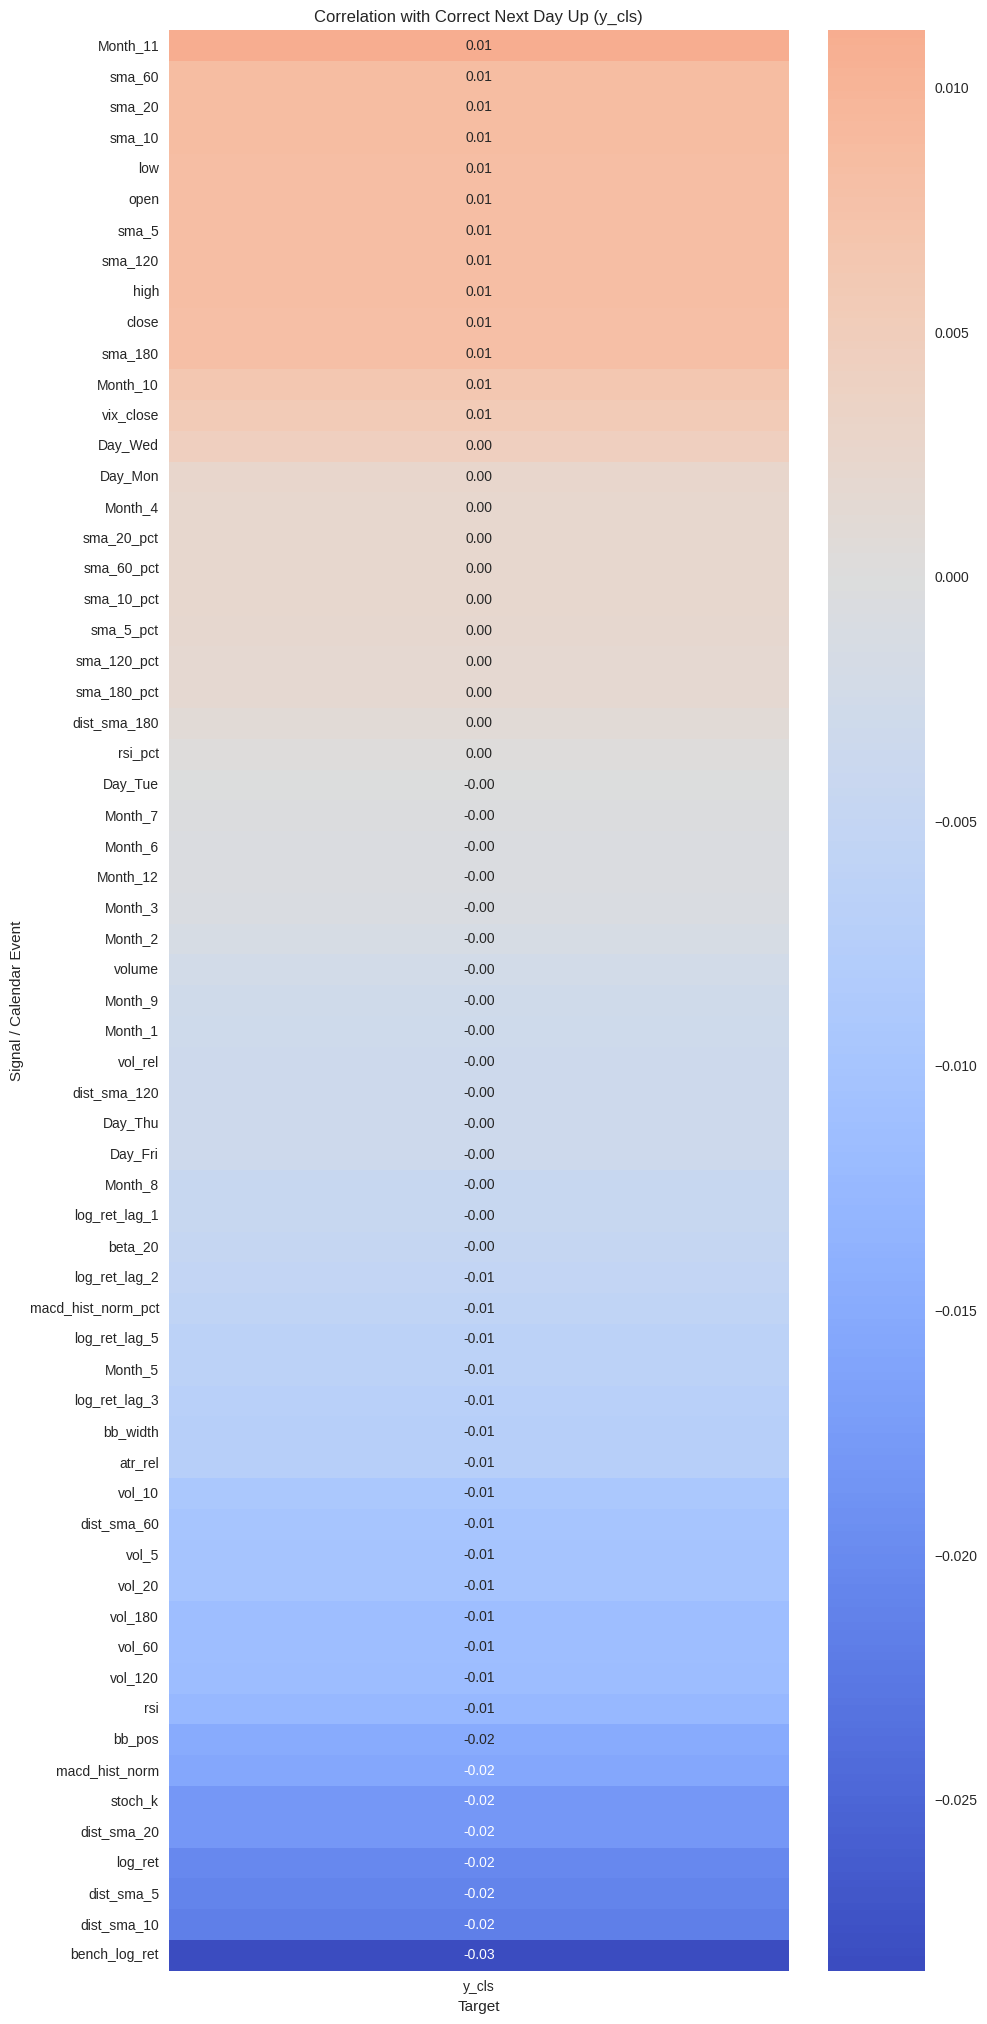

In [44]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def analyze_strategy_performance(bt_result, panel_data, feature_cols):
    """
    Generates a performance summary table and a feature correlation heatmap.
    """
    # --- 1. Summary Statistics Table ---
    print("\n=== Strategy Performance Summary ===")
    
    daily_ret = bt_result.daily['day_ret']
    
    # Calculate Metrics
    total_return = bt_result.daily['equity'].iloc[-1] - 1
    ann_return = daily_ret.mean() * 252
    ann_vol = daily_ret.std() * np.sqrt(252)
    sharpe = (ann_return / ann_vol) if ann_vol != 0 else 0
    
    # Drawdown
    cum_ret = (1 + daily_ret).cumprod()
    peak = cum_ret.cummax()
    drawdown = (cum_ret - peak) / peak
    max_dd = drawdown.min()
    
    # precision
    precision = bt_result.cls_report['precision']
    
    # Create Table
    stats_df = pd.DataFrame({
        'Metric': ['Total Return', 'Annualized Return', 'Annualized Volatility', 
                   'Sharpe Ratio', 'Max Drawdown', 'Directional precision'],
        'Value': [f"{total_return:.2%}", f"{ann_return:.2%}", f"{ann_vol:.2%}", 
                  f"{sharpe:.2f}", f"{max_dd:.2%}", f"{precision:.2%}"]
    })
    
    # Display simple text table
    print(stats_df.to_string(index=False))
    
    # --- 2. Feature & Calendar Correlation Analysis ---
    print("\n=== Feature Correlation with 'Next Day Up' ===")
    
    # Prepare Analysis Data
    analysis_df = panel_data.copy()
    
    # Add Calendar Features (One-Hot Encoded for Correlation)
    analysis_df['Month'] = analysis_df.index.month
    analysis_df['DayOfWeek'] = analysis_df.index.dayofweek
    
    # Create dummy variables for specific months/days
    # e.g., "Is_Monday", "Is_January"
    dummies = pd.get_dummies(analysis_df['Month'], prefix='Month')
    dummies_dow = pd.get_dummies(analysis_df['DayOfWeek'], prefix='Day')
    
    # Rename columns for clarity (Day 0 = Monday)
    day_map = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri'}
    dummies_dow.columns = [f"Day_{day_map.get(int(c.split('_')[-1]), c)}" for c in dummies_dow.columns]
    
    analysis_df = pd.concat([analysis_df, dummies, dummies_dow], axis=1)
    
    # Select Columns: Original Features + New Calendar Dummies + Target
    calendar_cols = dummies.columns.tolist() + dummies_dow.columns.tolist()
    cols_to_analyze = feature_cols + calendar_cols + ['y_cls']
    
    # Filter for existing columns only
    valid_cols = [c for c in cols_to_analyze if c in analysis_df.columns]
    corr_data = analysis_df[valid_cols]
    
    # Calculate Correlation Matrix
    corr_matrix = corr_data.corr()
    
    # Isolate correlations with the Target ('y_cls')
    target_corr = corr_matrix[['y_cls']].drop('y_cls')
    target_corr = target_corr.sort_values(by='y_cls', ascending=False)
    
    # Plot Heatmap
    plt.figure(figsize=(10, len(target_corr) * 0.4))  # Adjust height based on number of features
    sns.heatmap(target_corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', cbar=True)
    plt.title('Correlation with Correct Next Day Up (y_cls)')
    plt.xlabel('Target')
    plt.ylabel('Signal / Calendar Event')
    plt.show()

# --- Execute ---
# Ensure you pass the 'bt' object from your backtest and the 'panel' dataframe
if 'bt' in locals() and 'panel' in locals():
    analyze_strategy_performance(bt, panel, FEATURES)
else:
    print("Error: 'bt' or 'panel' variables not found. Please run the backtest first.")

## Additional diagnostics to run (confusion matrix + random baseline)
- Confusion matrix: in the executed notebook, use the stored backtest outputs (`bt.preds`, `bt.daily`) to visualize true vs predicted labels. Example cell to add/run:
  ```
  ```
- Random “always buy one stock” baseline: compare against a naive policy that picks one random ticker each day (no signals) and buys it. Add a cell like:
  ```python
  
  ```
  Then compute the same summary metrics (total return, Sharpe, drawdown, precision if you create random labels) and plot equity to contrast against the XGBoost strategy.
- Re-run `make run` to refresh the executed notebook; the new plots/tables will land in `artifacts/stonks-executed.ipynb` and inline in the notebook UI.


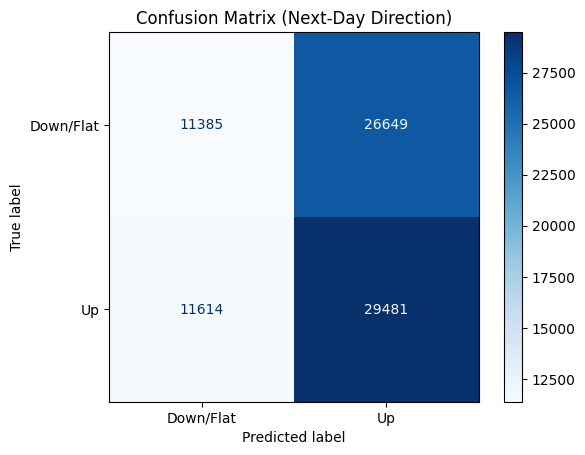

In [3]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Check if y_true is available
if 'y_true' in bt.preds.columns:
    y_true = bt.preds['y_true']
    
    # Determine y_hat (predictions) based on available columns
    if 'p_up' in bt.preds.columns:
        # Use 'p_up' from walk_forward_with_tuning
        # Using 0.5 as default threshold since the dynamic threshold isn't stored row-wise
        y_hat = (bt.preds['p_up'] > 0.5).astype(int)
        
    elif 'prob' in bt.preds.columns:
        # Handle cases from other backtest functions
        threshold = bt.preds['threshold'] if 'threshold' in bt.preds.columns else 0.5
        y_hat = (bt.preds['prob'] >= threshold).astype(int)
        
    elif 'y_pred' in bt.preds.columns:
        # Use pre-calculated predictions if available
        y_hat = bt.preds['y_pred']
        
    else:
        raise KeyError("Could not find probability or prediction column ('p_up', 'prob', or 'y_pred') in bt.preds")

    # Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_hat, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Down/Flat', 'Up'])
    disp.plot(values_format='d', cmap='Blues')
    plt.title('Confusion Matrix (Next-Day Direction)')
    plt.show()

else:
    print("Error: 'y_true' column missing from predictions, cannot plot confusion matrix.")

Running Random Baseline Simulation...


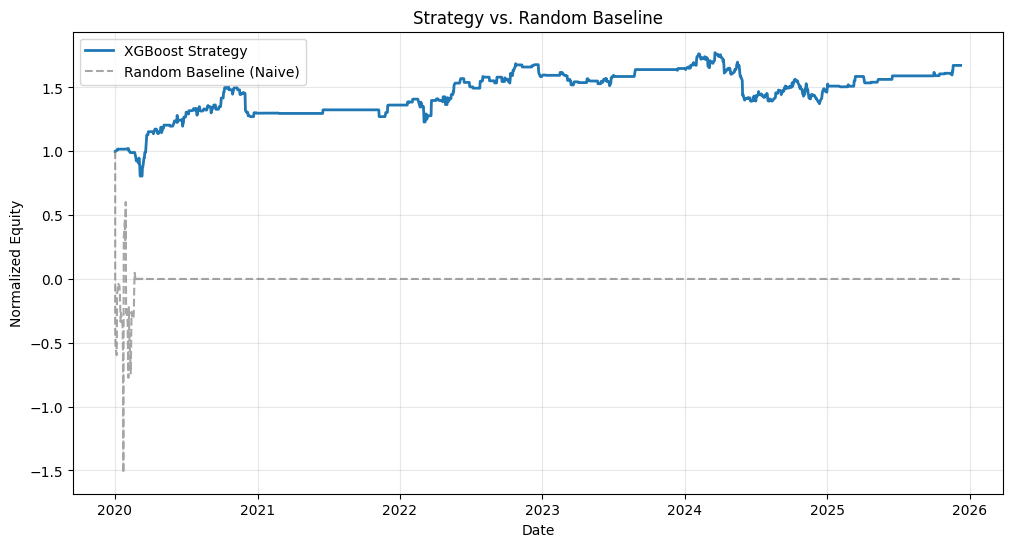

Random Baseline Sharpe: 0.268


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def run_random_baseline(panel_data, cfg):
    print("Running Random Baseline Simulation...")
    
    # Filter for backtest period
    test_data = panel_data[panel_data.index >= pd.Timestamp(cfg.backtest_start)].copy()
    dates = sorted(test_data.index.unique())
    
    equity_curve = [1.0]
    current_equity = 1.0
    tc = cfg.transaction_cost_bps / 10000.0
    
    # Set random seed for reproducibility
    np.random.seed(cfg.random_state)

    for d in dates:
        # Get data for this day
        day_slice = test_data.loc[d]
        
        # Get available tickers
        if isinstance(day_slice, pd.Series): # Handle single row case
             tickers = [day_slice['ticker']]
             returns = [day_slice['y_reg']] # Using y_reg as proxy for next day return
        else:
            tickers = day_slice['ticker'].values
            returns = day_slice['y_reg'].values # Using y_reg (horizon return)
            
        # Randomly select 'top_k' tickers
        if len(tickers) > 0:
            # Pick indices
            indices = np.random.choice(len(tickers), size=min(cfg.top_k, len(tickers)), replace=False)
            
            # Calculate mean return of random picks
            day_return = np.mean(returns[indices])
            
            # Apply transaction costs (assuming full turnover for random strategy)
            day_return -= tc * 2 # Entry + Exit costs roughly
            
            current_equity *= (1 + day_return)
        
        equity_curve.append(current_equity)
        
    return pd.Series(equity_curve, index=[dates[0]] + dates)

# Run the baseline
random_equity = run_random_baseline(panel, CFG)

# Plot Comparison
plt.figure(figsize=(12, 6))
plt.plot(bt.daily['equity'], label='XGBoost Strategy', linewidth=2)
plt.plot(random_equity, label='Random Baseline (Naive)', color='gray', linestyle='--', alpha=0.7)
plt.title("Strategy vs. Random Baseline")
plt.ylabel("Normalized Equity")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Print Baseline Metrics
rnd_ret = random_equity.pct_change().mean() * 252
rnd_vol = random_equity.pct_change().std() * np.sqrt(252)
rnd_sharpe = rnd_ret / rnd_vol if rnd_vol != 0 else 0
print(f"Random Baseline Sharpe: {rnd_sharpe:.3f}")

In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd

# 1. Define Helper to get predictions safely
def get_predictions(df, threshold=0.5):
    # Check for ground truth
    if 'y_true' not in df.columns:
        raise ValueError("Error: 'y_true' column missing from predictions.")
    
    y_true = df['y_true']
    
    # Check for Probability columns and convert to binary predictions
    if 'p_up' in df.columns:
        y_pred = (df['p_up'] > threshold).astype(int)
    elif 'prob' in df.columns:
        y_pred = (df['prob'] > threshold).astype(int)
    elif 'y_pred' in df.columns:
        y_pred = df['y_pred']
    else:
        raise ValueError("Error: No prediction column ('p_up', 'prob', or 'y_pred') found.")
        
    return y_true, y_pred

# 2. Calculate and Print Stats
try:
    # Get the data (adjust threshold if you want to test stricter probabilities)
    y_true, y_pred = get_predictions(bt.preds, threshold=0.5)

    # Calculate Metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print("--- Classification Metrics ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    
    print("\n--- Detailed Report ---")
    print(classification_report(y_true, y_pred, target_names=['Down/Flat', 'Up'], zero_division=0))

except Exception as e:
    print(e)

--- Classification Metrics ---
Accuracy:  0.5164
Precision: 0.5252
Recall:    0.7174
F1 Score:  0.6064

--- Detailed Report ---
              precision    recall  f1-score   support

   Down/Flat       0.50      0.30      0.37     38034
          Up       0.53      0.72      0.61     41095

    accuracy                           0.52     79129
   macro avg       0.51      0.51      0.49     79129
weighted avg       0.51      0.52      0.49     79129

